# DL4CV PA01-Q2: Softmax and Cross-Entropy



### To-do

1. Fill in Your ID and Name.
2. (Programming) In `softmax.py`, implement **softmax_forward()** function.
3. (Programming) In `softmax.py`, implement **softmax_backward()** function.
4. (Programming) In `softmax.py`, implement **cross_entropy_forward()** function.
5. (Programming) In `softmax.py`, implement **cross_entropy_backward()** function.
6. (Programming) In `softmax.py`, implement **train()** function in `class LinearClassifier`.
7. (Programming) In `softmax.py`, implement **predict()** function in `class LinearClassifier`.
8. (Save Outputs) Successfully Run all the **code cells** in `Q2_softmax.ipynb`, $\color{red}{\text{MUST}}$ save the outputs.
9. Submit $\color{red}{\mathtt{StudentID\_StudentName.zip}}$ file to Plato before deadline.


---

## Softmax and Cross-Entropy Programming Assignment

In this Programming Assignment you will:
    
- implement **linear Classifier** with **softmax** as output. Use **cross-entropy** as loss function.
- **check backward pass gradient** using numerical gradient
- **optimize** the loss function with **SGD**
- **visualize** the final learned weights

---

## Setup Code

### Google Colab Setup (Skip If Local Machine)

Unzip the `PA01.zip` file, upload entire `DeepLearning4ComputerVision` folder into Google drivers `My Drive` folder.

Next we need to run a few commands to set up our environment on Google Colab. If you are running this notebook on a local machine you can skip this section.

Run the following cell to mount your Google Drive. Follow the link, sign in to your Google account (the same account you used to store this notebook!) and copy the authorization code into the text box that appears below.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

GOOGLE_DRIVE_PATH_AFTER_MYDRIVE = 'DeepLearning4ComputerVision/PA01'

import os
import sys

#sys.path.append('/content/drive/My Drive/{}'.format(GOOGLE_DRIVE_PATH_AFTER_MYDRIVE)) # if not working, try this line instead
os.chdir('/content/drive/My Drive/{}'.format(GOOGLE_DRIVE_PATH_AFTER_MYDRIVE))

# Print current working directory
print("Current Working Directory:", os.getcwd())

# List files to make sure your data is visible
print("Available Files:", os.listdir())

If the output shows
> Mounted at /content/drive
> 
> Current Working Directory: /content/drive/My Drive/DeepLearning4ComputerVision/PA01
> 
> Available Files: ['datasets', 'dlcv', 'knn.py', 'softmax.py', ...]

Then, the Google Colab is working correctly.

### python env and ipynb setup (Local Machine Run from here) (Google Colab run this)

In [2]:
import sys
import importlib
sys.modules["imp"] = importlib
# Notebook will reload external python modules;
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
# This is a bit of magic to make matplotlib figures appear inline in the notebook
# rather than in a new window.
%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

def rel_error(x, y):
  """ returns relative error """
  return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))


## CIFAR-10 Data Loading and Preprocessing

In [3]:
import random
import numpy as np
from dlcv.data_utils import load_CIFAR10


# Load the raw CIFAR-10 data.
cifar10_dir = 'datasets/cifar-10-batches-py'

# Cleaning up variables to prevent loading data multiple times (which may cause memory issue)
try:
   del X_train, y_train
   del X_test, y_test
   print('Clear previously loaded data.')
except:
   pass

X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

# As a sanity check, we print out the size of the training and test data.
print('Training data shape: ', X_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


In [4]:
# Split the data into train, val, and test sets. In addition we will
# create a small development set as a subset of the training data;
# we can use this for development so our code runs faster.
num_training = 49000
num_validation = 1000
num_test = 1000
num_dev = 500

# Our validation set will be num_validation points from the original
# training set.
mask = range(num_training, num_training + num_validation)
X_val = X_train[mask]
y_val = y_train[mask]

# Our training set will be the first num_train points from the original
# training set.
mask = range(num_training)
X_train = X_train[mask]
y_train = y_train[mask]

# We will also make a development set, which is a small subset of
# the training set.
mask = np.random.choice(num_training, num_dev, replace=False)
X_dev = X_train[mask]
y_dev = y_train[mask]

# We use the first num_test points of the original test set as our
# test set.
mask = range(num_test)
X_test = X_test[mask]
y_test = y_test[mask]

print('Train data shape: ', X_train.shape)
print('Train labels shape: ', y_train.shape)
print('Validation data shape: ', X_val.shape)
print('Validation labels shape: ', y_val.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Train data shape:  (49000, 32, 32, 3)
Train labels shape:  (49000,)
Validation data shape:  (1000, 32, 32, 3)
Validation labels shape:  (1000,)
Test data shape:  (1000, 32, 32, 3)
Test labels shape:  (1000,)


In [5]:
# Preprocessing: reshape the image data into rows
X_train = np.reshape(X_train, (X_train.shape[0], -1))
X_val = np.reshape(X_val, (X_val.shape[0], -1))
X_test = np.reshape(X_test, (X_test.shape[0], -1))
X_dev = np.reshape(X_dev, (X_dev.shape[0], -1))

# As a sanity check, print out the shapes of the data
print('Training data shape: ', X_train.shape)
print('Validation data shape: ', X_val.shape)
print('Test data shape: ', X_test.shape)
print('dev data shape: ', X_dev.shape)

Training data shape:  (49000, 3072)
Validation data shape:  (1000, 3072)
Test data shape:  (1000, 3072)
dev data shape:  (500, 3072)


[130.64189796 135.98173469 132.47391837 130.05569388 135.34804082
 131.75402041 130.96055102 136.14328571 132.47636735 131.48467347]


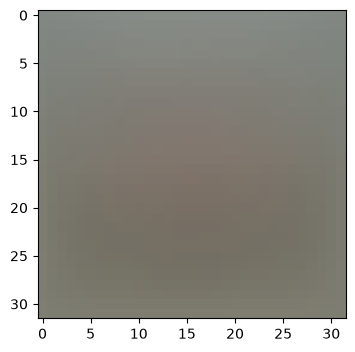

(49000, 3073) (1000, 3073) (1000, 3073) (500, 3073)


In [6]:
# Preprocessing: subtract the mean image
# first: compute the image mean based on the training data
mean_image = np.mean(X_train, axis=0)
print(mean_image[:10]) # print a few of the elements
plt.figure(figsize=(4,4))
plt.imshow(mean_image.reshape((32,32,3)).astype('uint8')) # visualize the mean image
plt.show()

# second: subtract the mean image from train and test data
X_train -= mean_image
X_val -= mean_image
X_test -= mean_image
X_dev -= mean_image

# third: append the bias dimension of ones (i.e. bias trick) so that our classifier
# only has to worry about optimizing a single weight matrix W.
X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
X_test = np.hstack([X_test, np.ones((X_test.shape[0], 1))])
X_dev = np.hstack([X_dev, np.ones((X_dev.shape[0], 1))])

print(X_train.shape, X_val.shape, X_test.shape, X_dev.shape)

## Linear Model, Softmax, Cross-Entropy 

Consider a multiclass classification model consisting of:

1. A linear transformation
2. A Softmax function
3. A cross-entropy loss

To simplify, there is **no bias term**. (The Bias term is included in [X]+[1] manner, so we don't need to add a bias term. This is to simplify the linear transformation operation, and focus on softmax and cross-entropy. In `twolayernet` and `cnn` programming assignments, you need to add bias term.)

Given 

$$
X\in\mathbb{R}^{B\times D}, W\in\mathbb{R}^{D\times K}, Y\in\mathbb{R}^{B\times K}
$$

where, B is batch size, D is feature X's dimension size, K is number of class. Y is onehot encoding (i.e. [0,0,1,0])

#### Forward Pass

The forward pass is

$$
XW=Z
$$

$$
\operatorname{Softmax}(Z)=S
$$

$$
\operatorname{CrossEntropy}(S,Y)=L.
$$

Therefore, the complete forward pass is

$$
\boxed{
XW=Z
\;\rightarrow\;
\operatorname{Softmax}(Z)=S
\;\rightarrow\;
\operatorname{CrossEntropy}(S,Y)=L.
}
$$

#### Backward Pass

After obtaining the loss \(L\), we want to determine how each element of \(W\) contributed to that loss.

Therefore, we calculate $\frac{\partial L}{\partial W}$.

Using the chain rule,

$$
\boxed{
\frac{\partial L}{\partial W}
=
\frac{\partial L}{\partial S}
\frac{\partial S}{\partial Z}
\frac{\partial Z}{\partial W}.
}
$$

#### Gradient Descent

Once we have calculated

$$
\frac{\partial L}{\partial W},
$$

we use it to update the weight matrix.

Gradient descent updates \(W\) as

$$
\boxed{
W_{\text{new}}
=
W_{\text{old}}
-
\eta
\frac{\partial L}{\partial W},
}
$$

where $\eta$ is the learning rate.

---

### Softmax Forward Pass

Given a toy problem

$$
X\in\mathbb{R}^{2\times 3}, W\in\mathbb{R}^{3\times 4}, Y\in\mathbb{R}^{2\times 4}
$$

The linear transformation is $XW=Z$, where $Z\in\mathbb{R}^{2\times4}$.

Softmax forward pass is

$$
S_{i}
=
\frac{e^{Z_{i}}}
{\sum_{j=1}^{K}e^{Z_{j}}}.
$$

For this toy problem $K = 4$.

### Implement softmax forward pass

open `softmax.py`, complete **softmax_forward()** function.

In [7]:
from softmax import softmax_forward

X = np.array([[2.0, 2.0, 1.0],[3.0, 4.0, 1.0]])
W = np.array([[1.0, 2.0, 3.0, 4.0],[1.0, 2.0, 3.0, 4.0],[1.0, 2.0, 3.0, 4.0]])

Z = X @ W  # Bias term is included in W, so we don't need to add a bias term to X

S, cache_softmax = softmax_forward(Z)

correct_out = np.array([[3.03841168e-07, 4.50940275e-05, 6.69254708e-03, 9.93262055e-01],
       [3.77386813e-11, 1.12497423e-07, 3.35350093e-04, 9.99664537e-01]])

# The error should be around e-8 or less
print("testing softmax_forward function...")
print("Softmax output error:", rel_error(S, correct_out))

testing softmax_forward function...
Softmax output error: 1.6614503005242187e-09


### Cross-Entropy Forward Pass

For the batch, define the average cross-entropy loss as

$$
L
=
-\frac{1}{B}
\sum_{b=1}^{B}
\sum_{i=1}^{K}
Y_{bi}\log S_{bi}.
$$

For this toy problem, $B = 2$, $L$ is a scalar. 

### Implement Cross-Entropy forward pass

open `softmax.py`, complete **cross_entropy_forward()** function.

In [8]:
from softmax import cross_entropy_forward


Y = np.array([0, 3])  # Y can be label ([3]) or one-hot encoding ([0, 0, 0, 1])
# Y = np.eye(4)[np.array([0, 3])]  # Convert labels to one-hot encoding (this works as well)

loss, cache_crossentropy = cross_entropy_forward(S, Y)  # Y's label or one-hot encoding both works

correct_loss = 7.50354813

# The error should be around e-8 or less
print("testing cross_entropy_forward function...")
print("Cross-entropy loss error:", rel_error(loss, correct_loss))

testing cross_entropy_forward function...
Cross-entropy loss error: 2.0978069172034387e-10


### Cross-Entropy Backward Pass

The derivative of Cross-Entropy is 

$$
\boxed{
\frac{\partial L}{\partial S}
=
-\frac{Y}{S}
}
$$

With Batch size $B$, it is

$$
\boxed{
\frac{\partial L}{\partial S}
=
-\frac{Y}{BS}
}
$$


### Implement Cross-Entropy backward pass

open `softmax.py`, complete **cross_entropy_backward()** function.

In [9]:
from softmax import cross_entropy_backward

dS = cross_entropy_backward(cache_crossentropy)

correct_dS = np.array([[-1.64559662e+06, -0.00000000e+00, -0.00000000e+00,
        -0.00000000e+00],
       [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00,
        -5.00167788e-01]])

# The error should be around e-8 or less
print("testing cross_entropy_backward function...")
print("Cross-entropy gradient error:", rel_error(dS, correct_dS))
print("Shape of S:", S.shape)
print("Shape of dL/dS:", dS.shape)


testing cross_entropy_backward function...
Cross-entropy gradient error: 1.7358475527375534e-09
Shape of S: (2, 4)
Shape of dL/dS: (2, 4)


Notice that $\frac{\partial L}{\partial S}$ and $S$ have the same shape.

### Softmax Backward Pass

For a \(K\)-class problem, the derivative of softmax is a Jacobian Matrix,

$$
\boxed{
\frac{\partial S}{\partial Z}
\in
\mathbb{R}^{K\times K}.
}
$$

where

$$
\boxed{
\frac{\partial S_i}{\partial Z_j}
=
\begin{cases}
S_i(1-S_i),&i=j,\\
-S_iS_j,&i\neq j.
\end{cases}
}
$$

In the back-propagation, the softmax backward pass is computing 

$$
\boxed{
\frac{\partial L}{\partial Z}
=
\frac{\partial L}{\partial S}
\frac{\partial S}{\partial Z}.
}
$$

For this toy problem


$$
\frac{\partial L}{\partial S}
:[2\times4],
$$

is from cross-entropy backward pass

and

$$
\frac{\partial S}{\partial Z}
:[4\times4].
$$

Therefore,

$$
\frac{\partial L}{\partial Z}
:[2\times4].
$$

Going further back-propagation, the derivative of 
$\frac{\partial Z}{\partial W}= X^T$.

Then 

$$
\boxed{
\frac{\partial L}{\partial W}
=
\frac{\partial L}{\partial S}
\frac{\partial S}{\partial Z}
\frac{\partial Z}{\partial W}
=
X^T
\frac{\partial L}{\partial Z}.
}
$$

Notice that, the $X$ is transposed and **moved to first position** in matrix dot production order.

$$
X^T
:[3\times 2],
$$

and

$$
\frac{\partial L}{\partial Z}
:[2\times 4],
$$

therefore

$$
\frac{\partial L}{\partial W}
:[3\times 4],
$$

$\color{red}{\text{(Important)}}$ So, $\frac{\partial L}{\partial W}$ has the same shape as $W$. And **only with the same shape**, we can do addition or subtraction operations on $\frac{\partial L}{\partial W}$ and $W$. For example, $W - \frac{\partial L}{\partial W}$, which is used in gradient descent process. 





### Implement Softmax backward pass

open `softmax.py`, complete **softmax_backward()** function.

In [10]:

from softmax import softmax_backward

dZ = softmax_backward(dS, cache_softmax)

correct_dZ = np.array([[-4.99999846e-01,  2.25470137e-05,  3.34627353e-03,
         4.96631026e-01],
       [ 1.88693406e-11,  5.62487117e-08,  1.67675046e-04,
        -1.67731314e-04]])

print("testing softmax_backward function...")
print("Softmax backward gradient error:", rel_error(dZ, correct_dZ))
print("Shape of Z:", Z.shape)
print("Shape of dL/dZ:", dZ.shape)

dW = X.T @ dZ

correct_dW = np.array([[-9.99999693e-01,  4.52627735e-05,  7.19557220e-03,
         9.92758858e-01],
       [-9.99999693e-01,  4.53190222e-05,  7.36324725e-03,
         9.92591127e-01],
       [-4.99999846e-01,  2.26032624e-05,  3.51394858e-03,
         4.96463295e-01]])

# The error should be around e-8 or less
print("testing weight W gradient...")
print("Softmax backward weight gradient error:", rel_error(dW, correct_dW))
print("Shape of W:", W.shape)
print("Shape of dL/dW:", dW.shape)

testing softmax_backward function...
Softmax backward gradient error: 2.079416886436598e-09
Shape of Z: (2, 4)
Shape of dL/dZ: (2, 4)
testing weight W gradient...
Softmax backward weight gradient error: 2.0605475301764255e-09
Shape of W: (3, 4)
Shape of dL/dW: (3, 4)


Notice that $\frac{\partial L}{\partial Z}$ and $Z$ have the same shape.
Notice that $\frac{\partial L}{\partial W}$ and $W$ have the same shape.

This is always true, in back-propagation, a tensor or matrix will have the same shape as its derivative respect to loss function. When trying to match dimensions of derivatives in long back-propagation, this trick is quite useful.

### Use Cifar10 Data

In [11]:
# Evaluate the naive implementation of the loss we provided for you:
import time

# generate a random Softmax classifier weight matrix of small numbers
W = np.random.randn(3073, 10) * 0.0001

Z = X_dev @ W
S, cache_softmax = softmax_forward(Z)

loss, cache_crossentropy = cross_entropy_forward(S, y_dev)

print('loss: %f' % (loss, ))

loss: 2.384287


In [12]:
# Once you've implemented the gradient, recompute it with the code below
# and gradient check it with the function we provided for you

# Compute the loss and its gradient at W.
def linear_model_softmax_cross_entropy(X, W, Y):
    Z = X_dev @ W
    S, cache_softmax = softmax_forward(Z)
    loss, cache_crossentropy = cross_entropy_forward(S, Y)
    dS = cross_entropy_backward(cache_crossentropy)
    dZ = softmax_backward(dS, cache_softmax)
    dW = X.T @ dZ
    return loss, dW

_, dW = linear_model_softmax_cross_entropy(X_dev, W, y_dev)
# Numerically compute the gradient along several randomly chosen dimensions, and
# compare them with your analytically computed gradient. The numbers should match
# almost exactly along all dimensions.
from dlcv.gradient_check import grad_check_sparse
f = lambda k: linear_model_softmax_cross_entropy(X_dev, k, y_dev)[0]
grad_numerical = grad_check_sparse(f, W, dW)


numerical: 2.571089 analytic: 2.571089, relative error: 8.760034e-09
numerical: 0.286911 analytic: 0.286911, relative error: 7.218380e-08
numerical: 0.955920 analytic: 0.955920, relative error: 5.368013e-08
numerical: 2.357476 analytic: 2.357476, relative error: 3.416256e-08
numerical: -0.387094 analytic: -0.387094, relative error: 1.132267e-07
numerical: -0.378856 analytic: -0.378856, relative error: 6.638661e-08
numerical: 0.846085 analytic: 0.846085, relative error: 5.074563e-08
numerical: -0.863109 analytic: -0.863109, relative error: 6.304777e-08
numerical: -1.076531 analytic: -1.076531, relative error: 5.655779e-08
numerical: 1.414756 analytic: 1.414756, relative error: 2.922421e-09


The **relative error** should be around e-8 or less

### Implement Training process of Linear model with softmax and cross-entropy, using SGD

open `softmax.py`, complete **train()** function in `class LinearClassifier`.

In [13]:
# and then run it with the code below.
from softmax import LinearClassifier
linear_model = LinearClassifier()
tic = time.time()
loss_hist = linear_model.train(X_train, y_train, learning_rate=1e-7, reg=2.5e4, num_iters=1500, verbose=True)
toc = time.time()
print('That took %fs' % (toc - tic))

iteration 0 / 1500: loss 778.501250
iteration 100 / 1500: loss 285.277985
iteration 200 / 1500: loss 105.749828
iteration 300 / 1500: loss 40.038882
iteration 400 / 1500: loss 16.023973
iteration 500 / 1500: loss 7.158251
iteration 600 / 1500: loss 3.918409
iteration 700 / 1500: loss 2.733924
iteration 800 / 1500: loss 2.368026
iteration 900 / 1500: loss 2.150623
iteration 1000 / 1500: loss 2.199708
iteration 1100 / 1500: loss 2.103258
iteration 1200 / 1500: loss 2.131464
iteration 1300 / 1500: loss 2.077904
iteration 1400 / 1500: loss 2.079752
That took 35.697069s


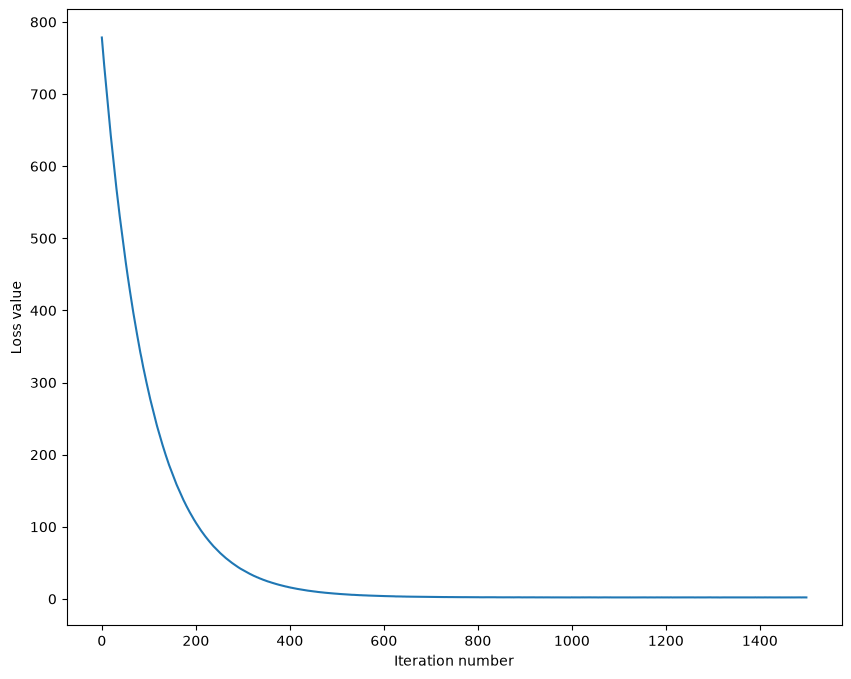

In [14]:
# A useful debugging strategy is to plot the loss as a function of
# iteration number:
plt.plot(loss_hist)
plt.xlabel('Iteration number')
plt.ylabel('Loss value')
plt.show()

### Implement prediction process of Linear model

open `softmax.py`, complete **predict()** function in `class LinearClassifier`.

In [15]:
# Write the LinearClassifier.predict function and evaluate the performance on
# training, validation and test set

y_train_pred = linear_model.predict(X_train)
print('training accuracy: %f' % (np.mean(y_train == y_train_pred), ))
y_val_pred = linear_model.predict(X_val)
print('validation accuracy: %f' % (np.mean(y_val == y_val_pred), ))
y_test_pred = linear_model.predict(X_test)
print('test accuracy: %f' % (np.mean(y_test == y_test_pred), ))

training accuracy: 0.323143
validation accuracy: 0.341000
test accuracy: 0.337000


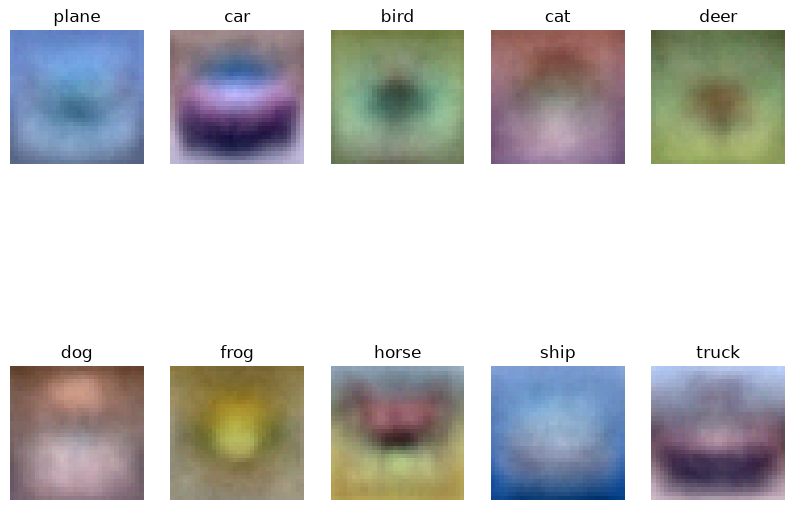

In [16]:
# Visualize the learned weights for each class.
# Depending on your choice of learning rate and regularization strength, these may
# or may not be nice to look at.
w = linear_model.W[:-1,:] # strip out the bias
w = w.reshape(32, 32, 3, 10)
w_min, w_max = np.min(w), np.max(w)
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Rescale the weights to be between 0 and 255
    wimg = 255.0 * (w[:, :, :, i].squeeze() - w_min) / (w_max - w_min)
    plt.imshow(wimg.astype('uint8'))
    plt.axis('off')
    plt.title(classes[i])